<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/07_Class_Group_Vulnerability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 — Class Group Vulnerability Analysis


This notebook investigates whether thin and small semantic classes show greater matched vulnerability than large structural classes.

The original thin/small group is now separated into:

### Static thin classes
- pole
- traffic light
- traffic sign

### Dynamic small classes
- person
- rider
- motorcycle
- bicycle

### Large / structural classes
- road
- building
- vegetation
- terrain
- sky

### Why the split is necessary

ACDC normal-reference and adverse images are scene correspondences captured at different times.

Static infrastructure is more naturally controlled by this scene-level correspondence.

Dynamic objects may differ between the two captures. Therefore, person, rider, motorcycle, and bicycle results must be interpreted as scene-level changes and not as object-level matched changes.

Both the **203-pair primary validation analysis** and the **1,003-pair expanded robustness analysis** are reported.

Class-support counts from Notebook 06 are also used so rare dynamic classes are not interpreted without considering how many matched scenes actually contain them.

Mount Drive and define paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CV_Project"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

MATCHED_RESULTS_DIR = (
    RESULTS_DIR
    / "matched_acdc"
)

GROUP_RESULTS_DIR = (
    RESULTS_DIR
    / "class_group_analysis"
)

GROUP_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Matched results folder:"
)

print(
    MATCHED_RESULTS_DIR
)

print(
    "\nGroup-analysis output folder:"
)

print(
    GROUP_RESULTS_DIR
)

Mounted at /content/drive
Matched results folder:
/content/drive/MyDrive/CV_Project/results/matched_acdc

Group-analysis output folder:
/content/drive/MyDrive/CV_Project/results/class_group_analysis


Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(
    "Libraries loaded."
)

Libraries loaded.


Load primary and expanded matched per-class results

In [ ]:
primary_path = (
    MATCHED_RESULTS_DIR
    / "matched_per_class_primary_203.csv"
)

expanded_path = (
    MATCHED_RESULTS_DIR
    / "matched_per_class_expanded_1003.csv"
)

primary_support_path = (
    MATCHED_RESULTS_DIR
    / "matched_class_support_primary_203.csv"
)

expanded_support_path = (
    MATCHED_RESULTS_DIR
    / "matched_class_support_expanded_1003.csv"
)


primary_df = pd.read_csv(
    primary_path
)

expanded_df = pd.read_csv(
    expanded_path
)

primary_support_df = pd.read_csv(
    primary_support_path
)

expanded_support_df = pd.read_csv(
    expanded_support_path
)


print(
    "Primary per-class rows:",
    len(primary_df)
)

print(
    "Expanded per-class rows:",
    len(expanded_df)
)

print(
    "Primary support rows:",
    len(primary_support_df)
)

print(
    "Expanded support rows:",
    len(expanded_support_df)
)

Primary per-class rows: 19
Expanded per-class rows: 19
Primary support rows: 76
Expanded support rows: 76


Define the revised class groups

In [ ]:
STATIC_THIN_CLASSES = [
    "pole",
    "traffic light",
    "traffic sign"
]

DYNAMIC_SMALL_CLASSES = [
    "person",
    "rider",
    "motorcycle",
    "bicycle"
]

LARGE_STRUCTURAL_CLASSES = [
    "road",
    "building",
    "vegetation",
    "terrain",
    "sky"
]


print(
    "Static thin classes:",
    len(
        STATIC_THIN_CLASSES
    )
)

print(
    "Dynamic small classes:",
    len(
        DYNAMIC_SMALL_CLASSES
    )
)

print(
    "Large / structural classes:",
    len(
        LARGE_STRUCTURAL_CLASSES
    )
)

Static thin classes: 3
Dynamic small classes: 4
Large / structural classes: 5


Assign each class to a revised group

In [ ]:
def assign_group(
    class_name
):

    if class_name in STATIC_THIN_CLASSES:
        return "Static Thin"

    if class_name in DYNAMIC_SMALL_CLASSES:
        return "Dynamic Small"

    if class_name in LARGE_STRUCTURAL_CLASSES:
        return "Large/Structural"

    return "Other"


for df in [
    primary_df,
    expanded_df
]:

    df[
        "class_group"
    ] = (
        df[
            "class_name"
        ]
        .apply(
            assign_group
        )
    )


display(
    expanded_df[
        [
            "class_name",
            "class_group"
        ]
    ]
)

,class_name,class_group
0,road,Large/Structural
1,sidewalk,Other
2,building,Large/Structural
3,wall,Other
4,fence,Other
5,pole,Static Thin
6,traffic light,Static Thin
7,traffic sign,Static Thin
8,vegetation,Large/Structural
9,terrain,Large/Structural


Check the selected groups

In [ ]:
for group_name in [
    "Static Thin",
    "Dynamic Small",
    "Large/Structural"
]:

    print(
        f"\n{group_name}"
    )

    classes = (
        expanded_df[
            expanded_df[
                "class_group"
            ] == group_name
        ][
            "class_name"
        ]
        .tolist()
    )

    for class_name in classes:
        print(
            "-",
            class_name
        )


Static Thin
- pole
- traffic light
- traffic sign

Dynamic Small
- person
- rider
- motorcycle
- bicycle

Large/Structural
- road
- building
- vegetation
- terrain
- sky


## Support-count reminder

The total number of matched scene pairs is not the effective sample size for every semantic class.

For a rare class, many pairs may contain no pixels belonging to that class.

The following tables therefore retain `pairs_with_class_both` from Notebook 06.

For dynamic classes, low support is especially important because the normal and adverse images may also contain different moving objects.

Show primary and expanded support for the revised groups

In [ ]:
selected_classes = (
    STATIC_THIN_CLASSES
    + DYNAMIC_SMALL_CLASSES
    + LARGE_STRUCTURAL_CLASSES
)


primary_selected_support = (
    primary_support_df[
        primary_support_df[
            "class_name"
        ].isin(
            selected_classes
        )
    ]
    .copy()
)

expanded_selected_support = (
    expanded_support_df[
        expanded_support_df[
            "class_name"
        ].isin(
            selected_classes
        )
    ]
    .copy()
)


primary_selected_support[
    "class_group"
] = (
    primary_selected_support[
        "class_name"
    ].apply(
        assign_group
    )
)

expanded_selected_support[
    "class_group"
] = (
    expanded_selected_support[
        "class_name"
    ].apply(
        assign_group
    )
)


print(
    "Primary validation support"
)

display(
    primary_selected_support[
        [
            "condition",
            "class_name",
            "class_group",
            "total_pairs",
            "pairs_with_class_normal",
            "pairs_with_class_adverse",
            "pairs_with_class_both",
            "low_pair_support"
        ]
    ]
)


print(
    "Expanded robustness support"
)

display(
    expanded_selected_support[
        [
            "condition",
            "class_name",
            "class_group",
            "total_pairs",
            "pairs_with_class_normal",
            "pairs_with_class_adverse",
            "pairs_with_class_both",
            "low_pair_support"
        ]
    ]
)

Primary validation support


,condition,class_name,class_group,total_pairs,pairs_with_class_normal,pairs_with_class_adverse,pairs_with_class_both,low_pair_support
0,fog,road,Large/Structural,50,50,50,50,False
2,fog,building,Large/Structural,50,48,47,47,False
5,fog,pole,Static Thin,50,50,50,50,False
6,fog,traffic light,Static Thin,50,31,27,26,False
7,fog,traffic sign,Static Thin,50,47,42,41,False
8,fog,vegetation,Large/Structural,50,50,48,48,False
9,fog,terrain,Large/Structural,50,46,32,32,False
10,fog,sky,Large/Structural,50,50,50,50,False
11,fog,person,Dynamic Small,50,31,18,11,False
12,fog,rider,Dynamic Small,50,8,5,1,True


Expanded robustness support


,condition,class_name,class_group,total_pairs,pairs_with_class_normal,pairs_with_class_adverse,pairs_with_class_both,low_pair_support
0,fog,road,Large/Structural,250,250,250,250,False
2,fog,building,Large/Structural,250,204,167,166,False
5,fog,pole,Static Thin,250,249,250,249,False
6,fog,traffic light,Static Thin,250,94,88,79,False
7,fog,traffic sign,Static Thin,250,224,197,190,False
8,fog,vegetation,Large/Structural,250,250,246,246,False
9,fog,terrain,Large/Structural,250,208,185,170,False
10,fog,sky,Large/Structural,250,250,250,250,False
11,fog,person,Dynamic Small,250,87,52,37,False
12,fog,rider,Dynamic Small,250,55,13,8,True


Compute mean matched IoU change by group and condition

In [ ]:
conditions = [
    "fog",
    "rain",
    "snow",
    "night"
]


def build_group_summary(
    per_class_df,
    analysis_set
):

    rows = []

    for condition in conditions:

        change_column = (
            f"{condition}_change"
        )

        for group_name in [
            "Static Thin",
            "Dynamic Small",
            "Large/Structural"
        ]:

            group_data = (
                per_class_df[
                    per_class_df[
                        "class_group"
                    ] == group_name
                ][
                    change_column
                ]
            )

            rows.append({
                "analysis_set":
                    analysis_set,

                "condition":
                    condition,

                "class_group":
                    group_name,

                "num_classes":
                    len(
                        group_data
                    ),

                "mean_change":
                    group_data.mean(),

                "median_change":
                    group_data.median(),

                "std_change":
                    group_data.std()
            })

    return pd.DataFrame(
        rows
    )


primary_group_summary = (
    build_group_summary(
        primary_df,
        "primary_validation_203"
    )
)

expanded_group_summary = (
    build_group_summary(
        expanded_df,
        "expanded_train_val_1003"
    )
)


print(
    "Primary validation group summary"
)

display(
    primary_group_summary
)


print(
    "Expanded robustness group summary"
)

display(
    expanded_group_summary
)

Primary validation group summary


,analysis_set,condition,class_group,num_classes,mean_change,median_change,std_change
0,primary_validation_203,fog,Static Thin,3,-0.055030,-0.063491,0.017320
1,primary_validation_203,fog,Dynamic Small,4,-0.221814,-0.183822,0.456785
2,primary_validation_203,fog,Large/Structural,5,-0.007751,0.001232,0.042913
3,primary_validation_203,rain,Static Thin,3,-0.015090,-0.039866,0.048655
4,primary_validation_203,rain,Dynamic Small,4,0.267201,0.305017,0.157016
5,primary_validation_203,rain,Large/Structural,5,0.001865,-0.003954,0.019792
6,primary_validation_203,snow,Static Thin,3,-0.010099,-0.021135,0.030101
7,primary_validation_203,snow,Dynamic Small,4,-0.042087,-0.080824,0.326451
8,primary_validation_203,snow,Large/Structural,5,0.102733,0.052237,0.143432
9,primary_validation_203,night,Static Thin,3,0.126980,0.176058,0.148811


Expanded robustness group summary


,analysis_set,condition,class_group,num_classes,mean_change,median_change,std_change
0,expanded_train_val_1003,fog,Static Thin,3,-0.008473,-0.013177,0.023104
1,expanded_train_val_1003,fog,Dynamic Small,4,-0.110059,-0.107474,0.119780
2,expanded_train_val_1003,fog,Large/Structural,5,0.032894,0.018625,0.043045
3,expanded_train_val_1003,rain,Static Thin,3,0.022640,0.018745,0.014867
4,expanded_train_val_1003,rain,Dynamic Small,4,0.031299,0.064147,0.171639
5,expanded_train_val_1003,rain,Large/Structural,5,0.009693,0.003508,0.034677
6,expanded_train_val_1003,snow,Static Thin,3,-0.036514,-0.020098,0.048104
7,expanded_train_val_1003,snow,Dynamic Small,4,0.132398,0.108636,0.076469
8,expanded_train_val_1003,snow,Large/Structural,5,0.125044,0.022820,0.207128
9,expanded_train_val_1003,night,Static Thin,3,0.086697,0.094527,0.090811


### Interpretation

For these group summaries:

**Matched IoU change = Normal-reference IoU − Adverse IoU**

- positive → lower measured IoU on the adverse side,
- negative → higher measured IoU on the adverse side.

The group mean is descriptive.

For the **Dynamic Small** group, it must not be interpreted as a fully controlled object-level weather effect because the moving objects may differ between normal and adverse captures.

Put expanded group means side-by-side

In [ ]:
expanded_group_pivot = (
    expanded_group_summary
    .pivot(
        index="condition",
        columns="class_group",
        values="mean_change"
    )
    .reset_index()
)

display(
    expanded_group_pivot
)

class_group,condition,Dynamic Small,Large/Structural,Static Thin
0,fog,-0.110059,0.032894,-0.008473
1,night,0.136588,0.278511,0.086697
2,rain,0.031299,0.009693,0.022640
3,snow,0.132398,0.125044,-0.036514


Calculate group differences

In [ ]:
expanded_group_pivot[
    "static_thin_minus_large"
] = (
    expanded_group_pivot[
        "Static Thin"
    ]
    -
    expanded_group_pivot[
        "Large/Structural"
    ]
)

expanded_group_pivot[
    "dynamic_small_minus_large"
] = (
    expanded_group_pivot[
        "Dynamic Small"
    ]
    -
    expanded_group_pivot[
        "Large/Structural"
    ]
)

display(
    expanded_group_pivot
)

class_group,condition,Dynamic Small,Large/Structural,Static Thin,static_thin_minus_large,dynamic_small_minus_large
0,fog,-0.110059,0.032894,-0.008473,-0.041367,-0.142953
1,night,0.136588,0.278511,0.086697,-0.191813,-0.141922
2,rain,0.031299,0.009693,0.022640,0.012947,0.021606
3,snow,0.132398,0.125044,-0.036514,-0.161558,0.007355


A positive group-difference value means that the selected thin/small group has a larger average matched IoU change than the large/structural group for that condition.

A negative value means the large/structural group has the larger average change.

These comparisons are descriptive rather than formal significance tests.

Overall average across all conditions

In [ ]:
def overall_group_summary(
    group_summary_df
):

    return (
        group_summary_df
        .groupby(
            [
                "analysis_set",
                "class_group"
            ],
            as_index=False
        )
        .agg(
            overall_mean_change=(
                "mean_change",
                "mean"
            ),

            overall_median_change=(
                "median_change",
                "mean"
            )
        )
    )


primary_overall = (
    overall_group_summary(
        primary_group_summary
    )
)

expanded_overall = (
    overall_group_summary(
        expanded_group_summary
    )
)


print(
    "Primary validation"
)

display(
    primary_overall
)


print(
    "Expanded robustness"
)

display(
    expanded_overall
)

Primary validation


,analysis_set,class_group,overall_mean_change,overall_median_change
0,primary_validation_203,Dynamic Small,0.052184,0.058034
1,primary_validation_203,Large/Structural,0.089030,0.046602
2,primary_validation_203,Static Thin,0.011690,0.012892


Expanded robustness


,analysis_set,class_group,overall_mean_change,overall_median_change
0,expanded_train_val_1003,Dynamic Small,0.047557,0.052692
1,expanded_train_val_1003,Large/Structural,0.111535,0.055688
2,expanded_train_val_1003,Static Thin,0.016088,0.019999


Plot expanded group matched change by condition

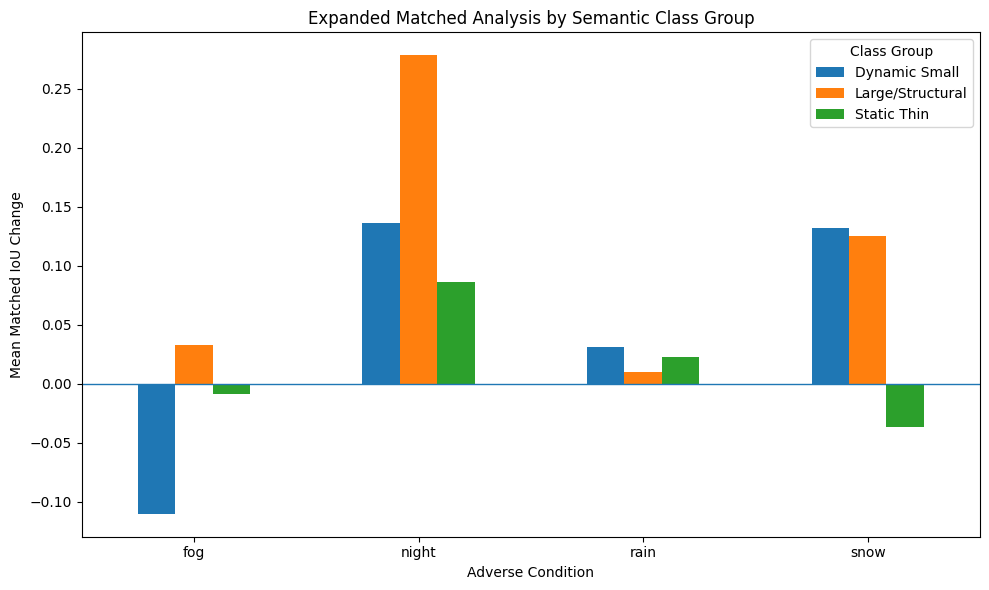

Saved: /content/drive/MyDrive/CV_Project/results/class_group_analysis/expanded_group_change_by_condition.png


In [ ]:
plot_df = (
    expanded_group_summary
    .pivot(
        index="condition",
        columns="class_group",
        values="mean_change"
    )
)

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel(
    "Mean Matched IoU Change"
)

plt.xlabel(
    "Adverse Condition"
)

plt.title(
    "Expanded Matched Analysis by Semantic Class Group"
)

plt.xticks(
    rotation=0
)

plt.axhline(
    0,
    linewidth=1
)

plt.legend(
    title="Class Group"
)

plt.tight_layout()

figure_path = (
    GROUP_RESULTS_DIR
    / "expanded_group_change_by_condition.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)

Overall expanded group comparison

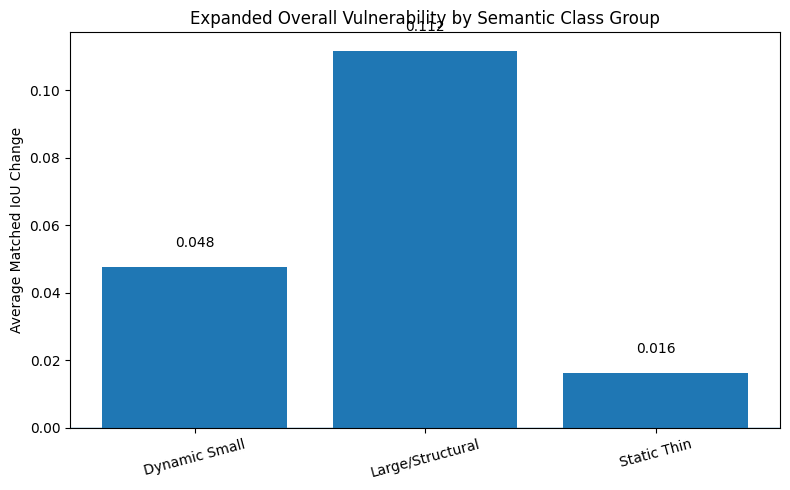

Saved: /content/drive/MyDrive/CV_Project/results/class_group_analysis/expanded_overall_group_vulnerability.png


In [ ]:
expanded_overall_plot = (
    expanded_overall
    .set_index(
        "class_group"
    )
)

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    expanded_overall_plot.index,
    expanded_overall_plot[
        "overall_mean_change"
    ]
)

plt.ylabel(
    "Average Matched IoU Change"
)

plt.title(
    "Expanded Overall Vulnerability by Semantic Class Group"
)

for bar, value in zip(
    bars,
    expanded_overall_plot[
        "overall_mean_change"
    ]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.005,

        f"{value:.3f}",

        ha="center",
        va="bottom"
    )

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

figure_path = (
    GROUP_RESULTS_DIR
    / "expanded_overall_group_vulnerability.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)

Show static thin classes individually

In [ ]:
static_thin_df = (
    expanded_df[
        expanded_df[
            "class_group"
        ] == "Static Thin"
    ][
        [
            "class_name",
            "fog_change",
            "rain_change",
            "snow_change",
            "night_change"
        ]
    ]
    .copy()
)

display(
    static_thin_df
)

,class_name,fog_change,rain_change,snow_change,night_change
5,pole,-0.013177,0.010109,0.001233,-0.007774
6,traffic light,-0.028864,0.018745,-0.020098,0.094527
7,traffic sign,0.016621,0.039066,-0.090677,0.173340


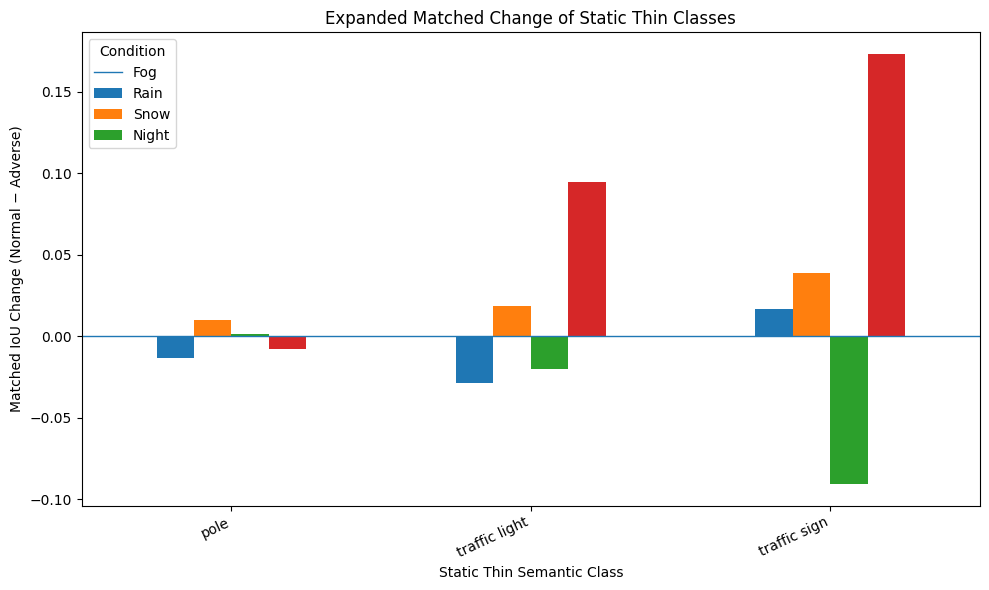

Saved: /content/drive/MyDrive/CV_Project/results/class_group_analysis/expanded_static_thin_class_change.png


In [ ]:
static_plot = (
    static_thin_df
    .set_index(
        "class_name"
    )
)

ax = static_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel(
    "Matched IoU Change (Normal − Adverse)"
)

plt.xlabel(
    "Static Thin Semantic Class"
)

plt.title(
    "Expanded Matched Change of Static Thin Classes"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.axhline(
    0,
    linewidth=1
)

plt.legend(
    [
        "Fog",
        "Rain",
        "Snow",
        "Night"
    ],
    title="Condition"
)

plt.tight_layout()

figure_path = (
    GROUP_RESULTS_DIR
    / "expanded_static_thin_class_change.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)

Show dynamic small classes individually

In [ ]:
dynamic_small_df = (
    expanded_df[
        expanded_df[
            "class_group"
        ] == "Dynamic Small"
    ][
        [
            "class_name",
            "fog_change",
            "rain_change",
            "snow_change",
            "night_change"
        ]
    ]
    .copy()
)

display(
    dynamic_small_df
)

,class_name,fog_change,rain_change,snow_change,night_change
11,person,0.024827,0.024228,0.071576,0.159551
12,rider,-0.250115,-0.202643,0.130712,0.229266
17,motorcycle,-0.056393,0.199544,0.086560,0.026170
18,bicycle,-0.158555,0.104066,0.240746,0.131365


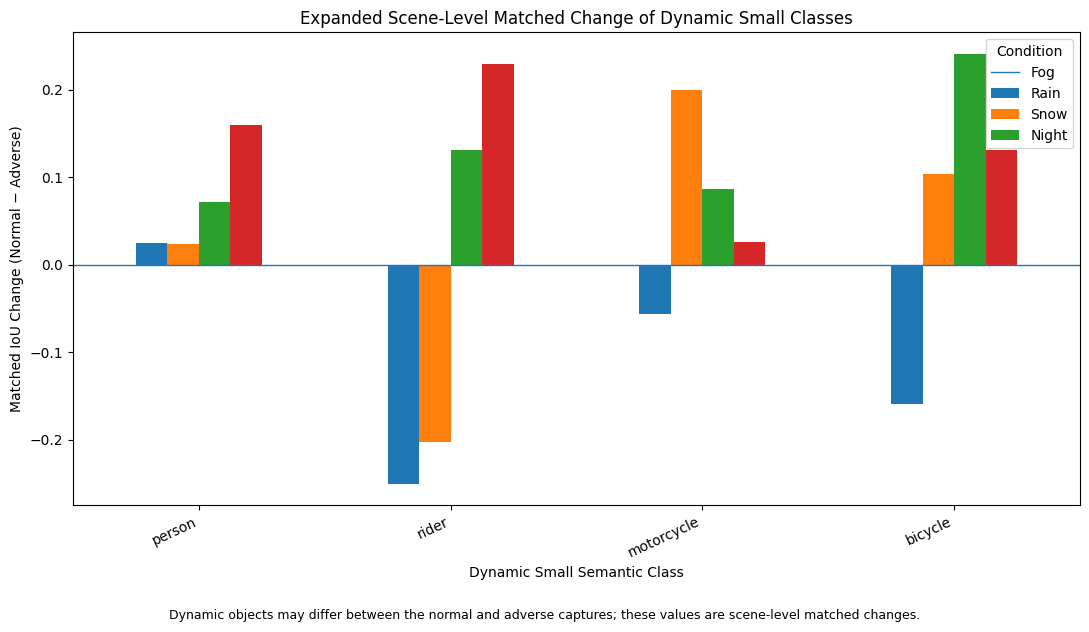

Saved: /content/drive/MyDrive/CV_Project/results/class_group_analysis/expanded_dynamic_small_class_change.png


In [ ]:
dynamic_plot = (
    dynamic_small_df
    .set_index(
        "class_name"
    )
)

ax = dynamic_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel(
    "Matched IoU Change (Normal − Adverse)"
)

plt.xlabel(
    "Dynamic Small Semantic Class"
)

plt.title(
    "Expanded Scene-Level Matched Change of Dynamic Small Classes"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.axhline(
    0,
    linewidth=1
)

plt.legend(
    [
        "Fog",
        "Rain",
        "Snow",
        "Night"
    ],
    title="Condition"
)

plt.figtext(
    0.5,
    -0.04,
    "Dynamic objects may differ between the normal and adverse captures; "
    "these values are scene-level matched changes.",
    ha="center",
    fontsize=9
)

plt.tight_layout()

figure_path = (
    GROUP_RESULTS_DIR
    / "expanded_dynamic_small_class_change.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)

Rank static thin and dynamic small classes by average expanded change

In [ ]:
def add_average_change(
    df
):

    result = (
        df.copy()
    )

    result[
        "average_change"
    ] = (
        result[
            [
                "fog_change",
                "rain_change",
                "snow_change",
                "night_change"
            ]
        ]
        .mean(
            axis=1
        )
    )

    return (
        result
        .sort_values(
            "average_change",
            ascending=False
        )
    )


static_thin_ranked = (
    add_average_change(
        static_thin_df
    )
)

dynamic_small_ranked = (
    add_average_change(
        dynamic_small_df
    )
)


print(
    "Static thin ranking"
)

display(
    static_thin_ranked[
        [
            "class_name",
            "average_change"
        ]
    ]
)


print(
    "Dynamic small ranking"
)

display(
    dynamic_small_ranked[
        [
            "class_name",
            "average_change"
        ]
    ]
)

Static thin ranking


,class_name,average_change
7,traffic sign,0.034588
6,traffic light,0.016077
5,pole,-0.002402


Dynamic small ranking


,class_name,average_change
18,bicycle,0.079406
11,person,0.070045
17,motorcycle,0.063970
12,rider,-0.023195


Summarize low-support dynamic classes

In [ ]:
low_support_dynamic = (
    expanded_selected_support[
        (
            expanded_selected_support[
                "class_group"
            ] == "Dynamic Small"
        )
        &
        (
            expanded_selected_support[
                "low_pair_support"
            ] == True
        )
    ][
        [
            "condition",
            "class_name",
            "total_pairs",
            "pairs_with_class_normal",
            "pairs_with_class_adverse",
            "pairs_with_class_both"
        ]
    ]
    .copy()
)

print(
    "Expanded dynamic-small rows "
    "with low pair support:"
)

display(
    low_support_dynamic
)

Expanded dynamic-small rows with low pair support:


,condition,class_name,total_pairs,pairs_with_class_normal,pairs_with_class_adverse,pairs_with_class_both
12,fog,rider,250,55,13,8
17,fog,motorcycle,250,45,15,9
18,fog,bicycle,250,40,17,8
31,rain,rider,250,70,14,5
50,snow,rider,250,124,16,9


## Interpretation of low-support dynamic classes

Even after expanding to 1,003 labeled scene pairs, some rare dynamic class-condition combinations may still have very few pairs in which the class appears on both sides.

For those combinations:

- wide or unstable uncertainty intervals are expected,
- the result should not be interpreted as a strong object-level condition effect,
- support counts should be reported alongside the IoU change.

This directly addresses the sample-size and dynamic-object limitations identified in the project feedback.

Save all revised group-analysis tables

In [ ]:
primary_group_summary.to_csv(
    GROUP_RESULTS_DIR
    / "primary_group_condition_summary.csv",
    index=False
)

expanded_group_summary.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_group_condition_summary.csv",
    index=False
)

expanded_group_pivot.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_group_vulnerability_difference.csv",
    index=False
)

primary_overall.to_csv(
    GROUP_RESULTS_DIR
    / "primary_overall_group_summary.csv",
    index=False
)

expanded_overall.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_overall_group_summary.csv",
    index=False
)

static_thin_ranked.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_static_thin_class_results.csv",
    index=False
)

dynamic_small_ranked.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_dynamic_small_class_results.csv",
    index=False
)

primary_selected_support.to_csv(
    GROUP_RESULTS_DIR
    / "primary_selected_class_support.csv",
    index=False
)

expanded_selected_support.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_selected_class_support.csv",
    index=False
)

low_support_dynamic.to_csv(
    GROUP_RESULTS_DIR
    / "expanded_low_support_dynamic_classes.csv",
    index=False
)

print(
    "Revised class-group analysis saved to:"
)

print(
    GROUP_RESULTS_DIR
)

Revised class-group analysis saved to:
/content/drive/MyDrive/CV_Project/results/class_group_analysis
